# Day 11: Reinforcement Learning – Stock Trading Bot

**Goal:** train an RL agent that learns *when to Buy, Sell or Hold* a stock to maximise returns, then **backtest** it on a period it never saw and compare it with a simple **Buy-and-Hold** strategy.

**Pipeline:** Problem definition → Environment (state, actions, reward) → Agent (PPO) → Backtest → Evaluation.

**Runtime:** a GPU is **not** needed (the network is tiny); the normal CPU runtime is fine. **Runtime → Run all**.

> This is a learning exercise, not financial advice. Real trading has slippage, taxes and risks not modelled here.

## 0. Install and settings

In [1]:
!pip install -q gymnasium stable-baselines3 yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO, DQN

# ---- Settings ----
TICKER      = "AAPL"
START, END  = "2015-01-01", "2025-01-01"
SPLIT_DATE  = "2022-01-01"   # train before this date, test (backtest) after it
WINDOW      = 10             # how many past days the agent sees
COST        = 0.001          # 0.1% transaction cost each time the position changes
TIMESTEPS   = 150_000        # training steps (more = longer training)
ALGO        = "PPO"          # "PPO" (actor-critic) or "DQN"
SEED        = 42

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. Get the price data (OHLCV)
Daily Open, High, Low, Close and Volume from Yahoo Finance. If the download fails, a **synthetic** price series is generated so the notebook still runs (clearly labelled).

ERROR:yfinance:Failed to get ticker 'AAPL' reason: Impersonating chrome152 is not supported
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['AAPL']: ImpersonateError('Impersonating chrome152 is not supported')


Download failed, using a synthetic price series instead: 
Data: SYNTHETIC, 2610 trading days, 2015-01-01 to 2025-01-01


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


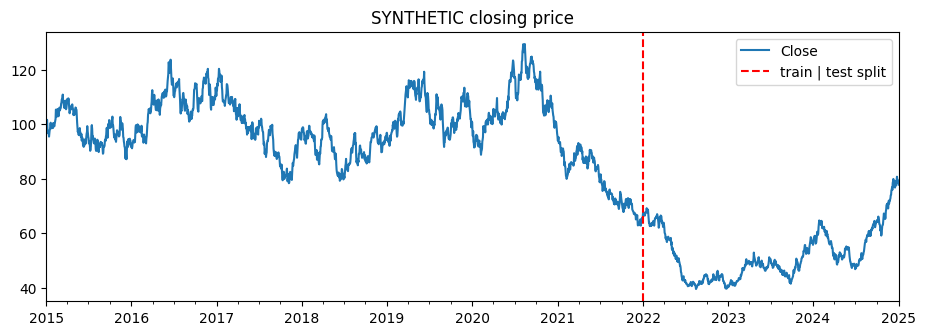

In [2]:
data_source = TICKER
try:
    import yfinance as yf
    raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw = raw[["Open", "High", "Low", "Close", "Volume"]].dropna()
    assert len(raw) > 500
except Exception as e:
    print("Download failed, using a synthetic price series instead:", e)
    data_source = "SYNTHETIC"
    rng = np.random.default_rng(SEED)
    dates = pd.bdate_range(START, END)
    close = 100 * np.exp(np.cumsum(rng.normal(0.0004, 0.015, len(dates))))
    raw = pd.DataFrame({"Open": close, "High": close * 1.01, "Low": close * 0.99,
                        "Close": close, "Volume": 1e6}, index=dates)

print(f"Data: {data_source}, {len(raw)} trading days, {raw.index[0].date()} to {raw.index[-1].date()}")
raw["Close"].plot(figsize=(11, 3.5), title=f"{data_source} closing price")
plt.axvline(pd.Timestamp(SPLIT_DATE), color="red", linestyle="--", label="train | test split")
plt.legend(); plt.show()

## 2. Features: what the agent can "see" (the State)
- **Recent daily returns** (last `WINDOW` days, in %): the short-term trend.
- **RSI (14)**: momentum, 0–100 (above 70 = "overbought", below 30 = "oversold").
- **MACD histogram** (as % of price): trend strength and direction.
- **Current position** (0 = holding cash, 1 = holding the stock).

In [3]:
df = raw.copy()
df["ret"] = np.log(df["Close"]).diff()                       # daily log return

delta = df["Close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
df["rsi"] = 100 - 100 / (1 + gain / (loss + 1e-9))

ema12 = df["Close"].ewm(span=12, adjust=False).mean()
ema26 = df["Close"].ewm(span=26, adjust=False).mean()
macd = ema12 - ema26
df["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / df["Close"] * 100

df = df.dropna()
train_df = df[df.index < SPLIT_DATE]
test_df  = df[df.index >= SPLIT_DATE]
print(f"Train: {len(train_df)} days ({train_df.index[0].date()} – {train_df.index[-1].date()})")
print(f"Test:  {len(test_df)} days ({test_df.index[0].date()} – {test_df.index[-1].date()})")
df[["ret", "rsi", "macd_hist"]].describe().round(3)

Train: 1813 days (2015-01-21 – 2021-12-31)
Test:  783 days (2022-01-03 – 2025-01-01)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,ret,rsi,macd_hist
count,2596.000,2596.000,2596.000
mean,-0.000,49.945,0.006
std,0.015,17.221,0.525
min,-0.054,9.303,-1.667
25%,-0.010,37.218,-0.336
50%,0.000,49.047,0.021
75%,0.010,62.594,0.376
max,0.048,94.888,1.505


## 3. The trading environment (Gymnasium)
- **Actions:** `0 = Sell` (go to cash), `1 = Hold` (keep current position), `2 = Buy` (hold the stock). Long-only, all-in.
- **Reward:** the next day's log return while holding the stock (0 in cash), **minus a 0.1% cost** every time the position changes. Summing log returns = total growth, so maximising reward = maximising profit.
- Each training episode starts at a random day (so the agent sees many different market situations); the backtest starts at the first test day.

In [4]:
class TradingEnv(gym.Env):
    def __init__(self, data, window=WINDOW, cost=COST, episode_len=252, random_start=True):
        super().__init__()
        self.ret = data["ret"].values.astype(np.float32)
        self.rsi = (data["rsi"].values / 100).astype(np.float32)
        self.macd = data["macd_hist"].values.astype(np.float32)
        self.window, self.cost = window, cost
        self.episode_len, self.random_start = episode_len, random_start
        self.action_space = spaces.Discrete(3)                  # 0 Sell, 1 Hold, 2 Buy
        self.observation_space = spaces.Box(-10, 10, shape=(window + 3,), dtype=np.float32)

    def _obs(self):
        recent = self.ret[self.t - self.window + 1: self.t + 1] * 100   # returns in %
        obs = np.concatenate([recent, [self.rsi[self.t], self.macd[self.t], self.pos]])
        return np.clip(obs, -10, 10).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        last_start = len(self.ret) - 2 - (self.episode_len if self.random_start else 0)
        if self.random_start:
            self.t = int(self.np_random.integers(self.window - 1, max(self.window, last_start)))
            self.end = self.t + self.episode_len
        else:
            self.t, self.end = self.window - 1, len(self.ret) - 2
        self.pos = 0.0
        return self._obs(), {}

    def step(self, action):
        new_pos = 1.0 if action == 2 else 0.0 if action == 0 else self.pos
        cost = self.cost * abs(new_pos - self.pos)
        reward = new_pos * float(self.ret[self.t + 1]) - cost
        self.pos = new_pos
        self.t += 1
        done = self.t >= self.end
        return self._obs(), reward, done, False, {"pos": self.pos, "cost": cost}

env = TradingEnv(train_df)
obs, _ = env.reset(seed=SEED)
print("Observation size:", obs.shape, "| first observation:", np.round(obs, 3))

Observation size: (13,) | first observation: [-2.472 -0.689 -0.041  2.692  0.235  1.514 -0.709 -1.737 -1.408 -1.048
  0.394 -0.227  0.   ]


## 4. Train the agent
- **PPO** (Proximal Policy Optimization) is an **actor-critic** method: the *actor* chooses actions, the *critic* estimates how good each situation is, and PPO makes small, safe policy updates.
- (Set `ALGO = "DQN"` to try a **Deep Q-Network** instead, which learns a value for each action.)

In [5]:
import time
train_env = TradingEnv(train_df)
if ALGO == "DQN":
    model = DQN("MlpPolicy", train_env, learning_rate=1e-4, buffer_size=50_000,
                exploration_fraction=0.3, seed=SEED, verbose=0)
else:
    model = PPO("MlpPolicy", train_env, n_steps=2048, batch_size=256, learning_rate=3e-4,
                ent_coef=0.01, gamma=0.99, seed=SEED, verbose=0)

t0 = time.time()
model.learn(total_timesteps=TIMESTEPS)
print(f"{ALGO} trained for {TIMESTEPS:,} steps in {(time.time() - t0)/60:.1f} min")
model.save(f"day11_{ALGO.lower()}_trader")

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO trained for 150,000 steps in 4.3 min


## 5. Backtest on the test period (data the agent never saw)
We compare 3 strategies over the same days:
- **RL agent** (deterministic actions)
- **Buy and Hold**: buy on day 1, never sell (the benchmark to beat)
- **Random agent**: random Buy/Sell/Hold (a sanity check; a useful agent must beat this)

In [6]:
def backtest(data, policy):
    env = TradingEnv(data, random_start=False)
    obs, _ = env.reset()
    rewards, positions, actions, done = [], [], [], False
    while not done:
        a = policy(obs)
        obs, r, done, _, info = env.step(a)
        rewards.append(r); positions.append(info["pos"]); actions.append(int(a))
    idx = data.index[env.window: env.window + len(rewards)]
    return pd.DataFrame({"reward": rewards, "pos": positions, "action": actions}, index=idx)

rl = backtest(test_df, lambda o: int(model.predict(o, deterministic=True)[0]))
rng = np.random.default_rng(SEED)
rnd = backtest(test_df, lambda o: int(rng.integers(0, 3)))
bh = backtest(test_df, lambda o: 2)            # always "Buy" = buy and hold

def metrics(r, pos):
    equity = np.exp(r.cumsum())
    daily = np.exp(r) - 1
    sharpe = np.sqrt(252) * daily.mean() / (daily.std() + 1e-12)
    drawdown = (equity / equity.cummax() - 1).min()
    trades = int((np.abs(np.diff(np.concatenate([[0], pos]))) > 0).sum())
    return {"Total return %": round((equity.iloc[-1] - 1) * 100, 1),
            "Sharpe ratio": round(sharpe, 2),
            "Max drawdown %": round(drawdown * 100, 1),
            "Days in market %": round(np.mean(pos) * 100, 1),
            "Trades": trades}

results = pd.DataFrame({f"RL agent ({ALGO})": metrics(rl["reward"], rl["pos"].values),
                        "Buy & Hold": metrics(bh["reward"], bh["pos"].values),
                        "Random": metrics(rnd["reward"], rnd["pos"].values)}).T
print(f"Backtest on {data_source}, {rl.index[0].date()} to {rl.index[-1].date()} (costs included)")
results

Backtest on SYNTHETIC, 2022-01-17 to 2024-12-31 (costs included)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Total return %,Sharpe ratio,Max drawdown %,Days in market %,Trades
RL agent (PPO),-1.6,0.07,-41.3,61.8,154.0
Buy & Hold,16.8,0.33,-42.8,100.0,1.0
Random,1.8,0.12,-51.3,51.8,275.0


## 6. Charts

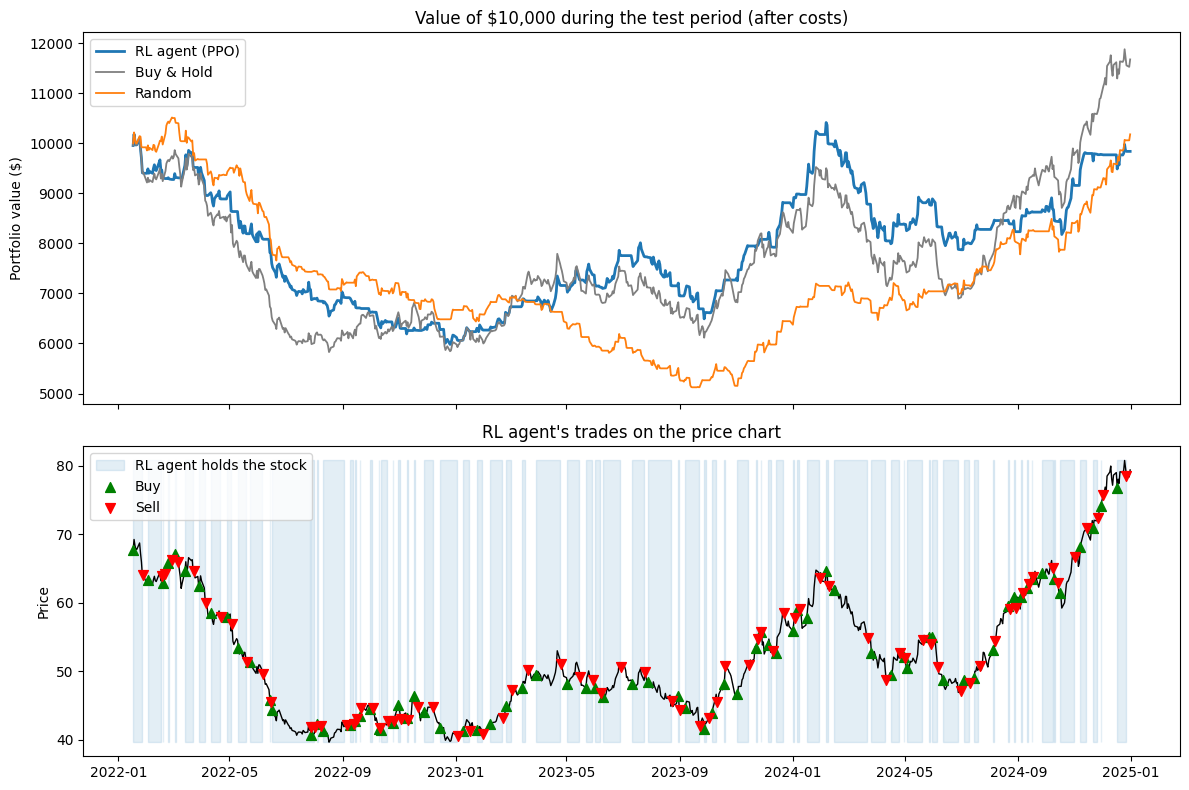

Action counts (0=Sell, 1=Hold, 2=Buy): {0: 207, 1: 280, 2: 285}


In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})

for name, res, c in [(f"RL agent ({ALGO})", rl, "tab:blue"), ("Buy & Hold", bh, "tab:gray"), ("Random", rnd, "tab:orange")]:
    ax[0].plot(np.exp(res["reward"].cumsum()) * 10_000, label=name, color=c, linewidth=2 if "RL" in name else 1.3)
ax[0].set_title("Value of $10,000 during the test period (after costs)")
ax[0].set_ylabel("Portfolio value ($)"); ax[0].legend()

price = test_df["Close"].reindex(rl.index)
ax[1].plot(price, color="black", linewidth=1)
in_market = rl["pos"] > 0
ax[1].fill_between(price.index, price.min(), price.max(), where=in_market, color="tab:blue", alpha=0.12,
                   label="RL agent holds the stock")
change = rl["pos"].diff().fillna(rl["pos"])
ax[1].scatter(price.index[change > 0], price[change > 0], marker="^", color="green", s=50, label="Buy", zorder=3)
ax[1].scatter(price.index[change < 0], price[change < 0], marker="v", color="red", s=50, label="Sell", zorder=3)
ax[1].set_title("RL agent's trades on the price chart"); ax[1].set_ylabel("Price"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

print("Action counts (0=Sell, 1=Hold, 2=Buy):", rl["action"].value_counts().sort_index().to_dict())

## 7. Conclusion (fill in after running)
- **Setup:** ___ daily data, trained ___ to ___, tested ___ to ___, 0.1% cost per trade.
- **Result:** RL agent return ___% vs Buy & Hold ___% vs Random ___%. Sharpe: ___ vs ___. Max drawdown: ___ vs ___.
- **Behaviour:** the agent was in the market ___% of the time and made ___ trades. It tends to ___ (e.g. stay out during falls / trade too often / copy buy-and-hold).
- **Why RL is hard here:** stock returns are very noisy; patterns from the training years may not repeat (non-stationary); costs punish frequent trading; one backtest period is not proof.
- **Next steps:** reward with a Sharpe-style penalty for volatility, add more features (volume, longer trends), walk-forward testing on several periods, try DQN vs PPO, multiple random seeds.